In [3]:
import pandas as pd
df = pd.read_csv("../data/precision_agriculture_dataset.csv")
print(df.shape)
df.head()

(15000, 32)


,timestamp,sensor_node_id,field_zone,latitude,longitude,crop_type,growth_stage,air_temperature_c,relative_humidity_pct,soil_temperature_c,...,leaf_wetness_pct,co2_ppm,evapotranspiration_mm,irrigation_status,irrigation_amount_l,water_flow_rate_l_min,battery_level_pct,signal_strength_dbm,sensor_status,environmental_condition
0,2024-01-01 00:00:00,SN_007,Zone_C,11.696902,78.726563,Tomato,Seedling,22.68,87.98,21.20,...,62.35,418.77,0.62,Off,0.00,0.00,69.23,-86.89,Active,High_Humidity
1,2024-01-01 00:30:00,SN_020,Zone_C,11.025794,79.390131,Cotton,Flowering,21.59,69.39,17.32,...,45.51,425.17,0.89,Off,0.00,0.00,88.45,-77.59,Active,Optimal
2,2024-01-01 01:00:00,SN_029,Zone_C,12.092548,78.785863,Maize,Seedling,19.60,79.59,19.86,...,42.12,493.87,0.50,Off,0.00,0.00,77.51,-48.27,Active,Adverse
3,2024-01-01 01:30:00,SN_015,Zone_D,12.923650,78.570311,Maize,Fruiting,20.51,77.78,18.18,...,49.81,457.19,0.74,On,40.54,4.63,83.10,-60.33,Active,Dry_Stress
4,2024-01-01 02:00:00,SN_011,Zone_B,12.202847,78.882257,Wheat,Fruiting,22.69,60.38,21.31,...,22.05,397.79,1.06,Off,0.00,0.00,81.62,-63.55,Active,Optimal


In [4]:
import numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split

RS = 42
TARGET = "environmental_condition"

df_dev, df_test = train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=RS)
print("full:", df.shape, "| dev:", df_dev.shape, "| test:", df_test.shape)

full: (15000, 32) | dev: (12000, 32) | test: (3000, 32)


In [5]:
display(pd.crosstab(df_dev["irrigation_status"], df_dev[TARGET]))

off = df_dev[df_dev.irrigation_status == "Off"][["irrigation_amount_l", "water_flow_rate_l_min"]]
print("amount and flow when Off (sum):", off.abs().sum().to_dict())

environmental_condition,Adverse,Dry_Stress,Heat_Stress,High_Humidity,Optimal
irrigation_status,,,,,
Off,2689,0,484,875,5106
On,0,2846,0,0,0


amount and flow when Off (sum): {'irrigation_amount_l': 0.0, 'water_flow_rate_l_min': 0.0}


In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

LEAK = ["irrigation_status", "irrigation_amount_l", "water_flow_rate_l_min"]
num_cols = [c for c in df.select_dtypes("number").columns if c not in LEAK]
X, y = df_dev[num_cols], df_dev[TARGET]
print(len(num_cols), "numeric features kept")

rows = []
for d in (2, 3, 4, 5, 6, 8):
    s = cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=RS),
                        X, y, cv=5, scoring="f1_macro").mean()
    rows.append((d, round(s, 3)))
display(pd.DataFrame(rows, columns=["tree_depth", "macro_F1_cv"]))

tree = DecisionTreeClassifier(max_depth=6, random_state=RS).fit(X, y)
imp = pd.Series(tree.feature_importances_, num_cols).sort_values(ascending=False)
display(imp.head(6).round(3).to_frame("importance"))

22 numeric features kept


,tree_depth,macro_F1_cv
0,2,0.553
1,3,0.679
2,4,0.961
3,5,0.985
4,6,0.996
5,8,1.000


,importance
soil_moisture_pct,0.448
relative_humidity_pct,0.290
air_temperature_c,0.262
soil_ec_ds_m,0.000
longitude,0.000
latitude,0.000


Features the rule uses: ['soil_moisture_pct', 'relative_humidity_pct', 'air_temperature_c']


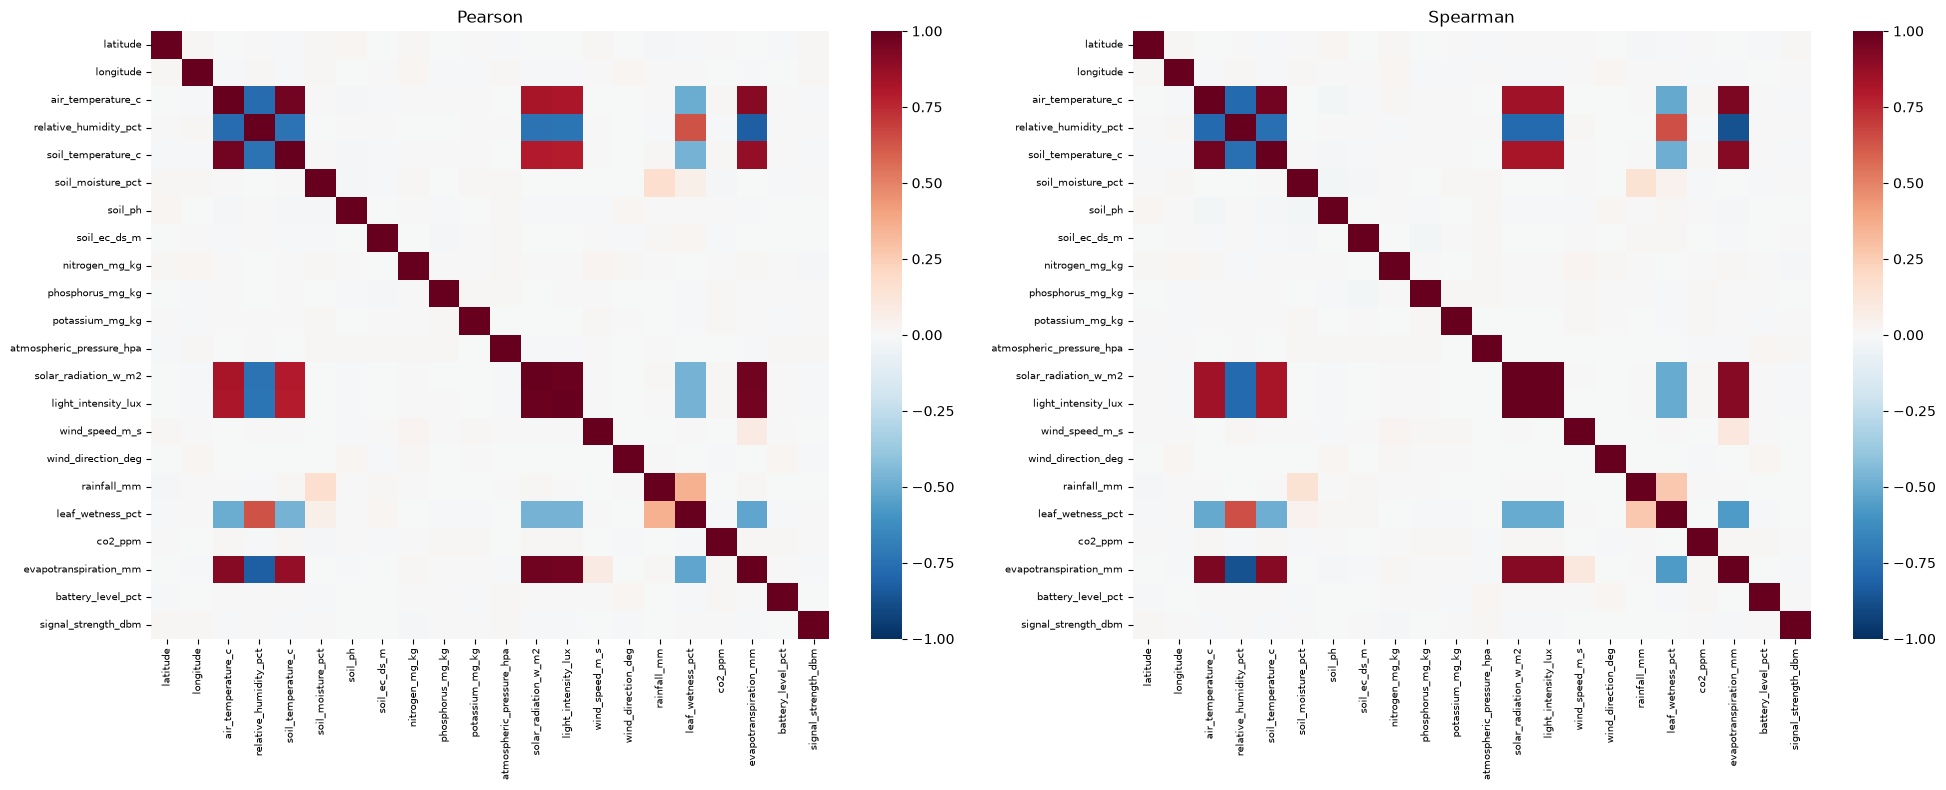

Pairs with |Pearson| >= 0.9:


,feature_a,feature_b,r
277,solar_radiation_w_m2,light_intensity_lux,0.989485
283,solar_radiation_w_m2,evapotranspiration_mm,0.973478
305,light_intensity_lux,evapotranspiration_mm,0.963314
48,air_temperature_c,soil_temperature_c,0.961379
63,air_temperature_c,evapotranspiration_mm,0.911739


In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

SIGNAL = imp[imp > 0.01].index.tolist()
print("Features the rule uses:", SIGNAL)

pear  = X.corr("pearson")
spear = X.corr("spearman")

fig, ax = plt.subplots(1, 2, figsize=(20, 8))
for a, m, t in zip(ax, [pear, spear], ["Pearson", "Spearman"]):
    sns.heatmap(m, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=a, xticklabels=True, yticklabels=True)
    a.set_title(t); a.tick_params(labelsize=7)
plt.tight_layout()
plt.savefig("../figures/correlation_heatmaps.png", dpi=130)
plt.show()

def pairs(m, thr):
    u = m.where(np.triu(np.ones(m.shape), 1).astype(bool)).stack().rename("r").reset_index()
    u.columns = ["feature_a", "feature_b", "r"]
    return u[u.r.abs() >= thr].sort_values("r", key=abs, ascending=False)

print("Pairs with |Pearson| >= 0.9:")
display(pairs(pear, 0.9))

In [8]:
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xs = StandardScaler().fit_transform(X)

def vif_table(cols):
    Z = StandardScaler().fit_transform(X[cols])
    return pd.Series([variance_inflation_factor(Z, i) for i in range(len(cols))],
                     index=cols).sort_values(ascending=False)

vif = vif_table(num_cols)
display(vif.round(1).head(10).to_frame("VIF"))

,VIF
evapotranspiration_mm,212948.6
solar_radiation_w_m2,87779.0
air_temperature_c,16336.0
relative_humidity_pct,4213.7
wind_speed_m_s,1308.0
light_intensity_lux,47.9
soil_temperature_c,13.2
leaf_wetness_pct,2.2
rainfall_mm,1.3
soil_moisture_pct,1.0


In [9]:
feats, vif_drops = list(num_cols), []

while True:
    v = vif_table(feats)
    candidates = v[~v.index.isin(SIGNAL)]        # ignore the protected features
    if candidates.iloc[0] < 10:                  # nothing left to remove
        break
    worst = candidates.index[0]
    vif_drops.append((worst, round(candidates.iloc[0], 1)))
    feats.remove(worst)

print("Removed (in order):", vif_drops)
display(vif_table(feats).round(2).head(6).to_frame("VIF after"))

Removed (in order): [('evapotranspiration_mm', np.float64(212948.6)), ('solar_radiation_w_m2', np.float64(50.2)), ('soil_temperature_c', np.float64(13.2))]


,VIF after
air_temperature_c,3.64
relative_humidity_pct,3.49
light_intensity_lux,3.22
leaf_wetness_pct,2.16
rainfall_mm,1.31
soil_moisture_pct,1.03


In [11]:
from sklearn.feature_selection import f_classif, mutual_info_classif

F, p = f_classif(X, y)                               # ANOVA F-test
mi   = mutual_info_classif(X, y, random_state=RS)    # mutual information

# Fisher ratio = variation between classes / variation within classes
mu = X.mean()
g = X.groupby(y)
between = sum(len(v) * (v.mean() - mu) ** 2 for _, v in g)
within  = sum(((v - v.mean()) ** 2).sum() for _, v in g)
fisher = between / within

scores = pd.DataFrame({"feature": num_cols, "anova_F": F, "anova_p": p,
                       "mutual_info": mi, "fisher_ratio": fisher.values}) \
           .sort_values("mutual_info", ascending=False).reset_index(drop=True)
display(scores.round(4))

,feature,anova_F,anova_p,mutual_info,fisher_ratio
0,soil_moisture_pct,3643.1103,0.0000,0.5983,1.2149
1,relative_humidity_pct,1054.3882,0.0000,0.3983,0.3516
2,air_temperature_c,785.2925,0.0000,0.3834,0.2619
3,evapotranspiration_mm,717.6381,0.0000,0.2629,0.2393
4,soil_temperature_c,701.0102,0.0000,0.2292,0.2338
5,solar_radiation_w_m2,570.6187,0.0000,0.1365,0.1903
6,light_intensity_lux,551.8492,0.0000,0.1166,0.1840
7,leaf_wetness_pct,359.6118,0.0000,0.0689,0.1199
8,rainfall_mm,31.3602,0.0000,0.0229,0.0105
9,wind_direction_deg,1.4560,0.2128,0.0107,0.0005


In [12]:
from scipy.stats import chi2_contingency

cat_cols = ["sensor_node_id", "field_zone", "crop_type", "growth_stage", "sensor_status"]
rows = []
for c in cat_cols:
    t = pd.crosstab(df_dev[c], df_dev[TARGET])
    chi2, p, dof, _ = chi2_contingency(t)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    rows.append((c, df_dev[c].nunique(), round(chi2, 1), p, round(v, 4)))

cat_scores = pd.DataFrame(rows, columns=["feature", "n_categories", "chi2", "p_value", "cramers_v"]) \
               .sort_values("cramers_v", ascending=False)
display(cat_scores)

,feature,n_categories,chi2,p_value,cramers_v
0,sensor_node_id,30,110.5,0.626306,0.0480
3,growth_stage,5,32.7,0.008043,0.0261
4,sensor_status,3,11.2,0.189302,0.0216
1,field_zone,5,15.5,0.490052,0.0180
2,crop_type,5,13.6,0.631944,0.0168


components for 90% variance: 15 | for 95%: 17 (out of 22)


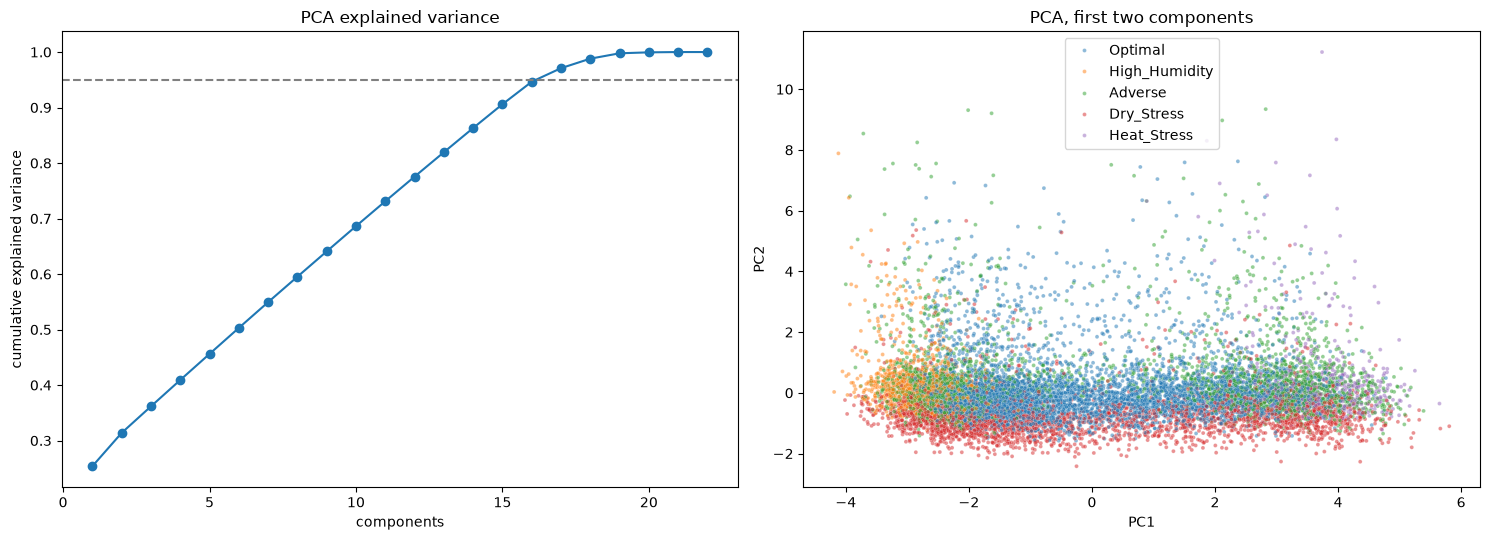

,PC1,PC2,PC3
evapotranspiration_mm,0.417,0.062,0.025
solar_radiation_w_m2,0.398,0.075,-0.008
air_temperature_c,0.396,0.063,-0.016
light_intensity_lux,0.396,0.074,-0.009
soil_temperature_c,0.386,0.068,-0.017
relative_humidity_pct,-0.367,0.021,0.003
leaf_wetness_pct,-0.265,0.433,-0.029
rainfall_mm,-0.016,0.744,-0.025


In [13]:
from sklearn.decomposition import PCA

pca = PCA(random_state=RS).fit(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)

n90 = int(np.argmax(cum >= 0.90) + 1)
n95 = int(np.argmax(cum >= 0.95) + 1)
print(f"components for 90% variance: {n90} | for 95%: {n95} (out of {len(num_cols)})")

Z = pca.transform(Xs)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].plot(range(1, len(cum) + 1), cum, marker="o")
ax[0].axhline(0.95, ls="--", c="grey")
ax[0].set(xlabel="components", ylabel="cumulative explained variance", title="PCA explained variance")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y.values, s=8, alpha=0.5, ax=ax[1])
ax[1].set(xlabel="PC1", ylabel="PC2", title="PCA, first two components")
plt.tight_layout()
plt.savefig("../figures/pca.png", dpi=130)
plt.show()

loadings = pd.DataFrame(pca.components_[:3].T, index=num_cols, columns=["PC1", "PC2", "PC3"])
display(loadings.reindex(loadings.PC1.abs().sort_values(ascending=False).index).head(8).round(3))

c:\Users\aneela\Desktop\precision-agriculture\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\aneela\Desktop\precision-agriculture\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


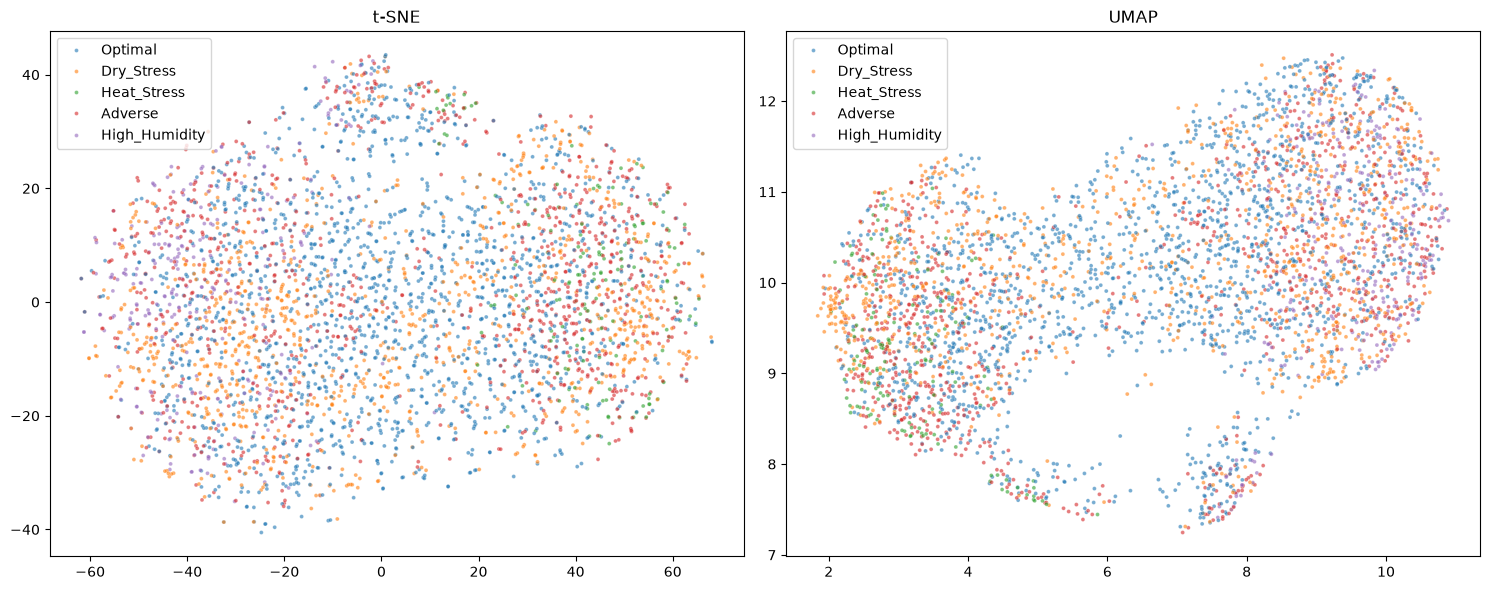

In [14]:
from sklearn.manifold import TSNE
import umap

idx = np.random.RandomState(RS).choice(len(Xs), 4000, replace=False)   # 4,000 random rows
Xsub, ysub = Xs[idx], y.values[idx]

tsne = TSNE(n_components=2, perplexity=30, random_state=RS, init="pca").fit_transform(Xsub)
um   = umap.UMAP(n_components=2, random_state=RS).fit_transform(Xsub)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, E, t in zip(ax, [tsne, um], ["t-SNE", "UMAP"]):
    sns.scatterplot(x=E[:, 0], y=E[:, 1], hue=ysub, s=8, alpha=0.6, ax=a)
    a.set_title(t)
plt.tight_layout()
plt.savefig("../figures/tsne_umap.png", dpi=130)
plt.show()

In [15]:
from sklearn.metrics import silhouette_score, silhouette_samples

sil_all = silhouette_score(Xsub, ysub)
print("overall silhouette:", round(sil_all, 3))

ss = silhouette_samples(Xsub, ysub)
display(pd.Series(ss).groupby(ysub).mean().sort_values().round(3).to_frame("mean_silhouette"))

# same score, but using only the 3 decisive features
sig_idx = [num_cols.index(c) for c in SIGNAL]
print("silhouette with only the 3 decisive features:",
      round(silhouette_score(Xsub[:, sig_idx], ysub), 3))

# class imbalance
cnt = y.value_counts()
print(cnt)
print("majority : minority =", round(cnt.max() / cnt.min(), 1), ": 1   (project limit 3 : 1)")

overall silhouette: -0.042


,mean_silhouette
Adverse,-0.154
Dry_Stress,-0.062
Optimal,-0.023
High_Humidity,0.151
Heat_Stress,0.180


silhouette with only the 3 decisive features: 0.016
environmental_condition
Optimal          5106
Dry_Stress       2846
Adverse          2689
High_Humidity     875
Heat_Stress       484
Name: count, dtype: int64
majority : minority = 10.5 : 1   (project limit 3 : 1)


In [16]:
# 1) Leakage
rows = [(f, "leakage", "encodes the target (irrigation On <=> Dry_Stress)") for f in LEAK]

# 2) Redundant (from the iterative VIF in Cell F)
for f, v in vif_drops:
    rows.append((f, "redundant", f"VIF {v} (collinear with kept features; signal features protected)"))

# 3) No signal (numeric): weak scores and not one of the 3 decisive features
weak = scores[(scores.anova_p > 0.05) & (scores.mutual_info < 0.005)
              & ~scores.feature.isin(SIGNAL)].feature.tolist()
for f in weak:
    rows.append((f, "no_signal", "ANOVA p > 0.05 and MI < 0.005 (candidate, test in week 2)"))

# 4) No signal (categorical)
for _, r in cat_scores[cat_scores.cramers_v < 0.05].iterrows():
    rows.append((r.feature, "no_signal", f"categorical, Cramer's V = {r.cramers_v} (< 0.05)"))

drop_df = pd.DataFrame(rows, columns=["feature", "category", "reason"])
display(drop_df)

kept = [c for c in df.columns if c not in set(drop_df.feature) | {TARGET, "timestamp"}]
print("Kept (timestamp is handled by Student 3):", kept)

# Export
vif_df = vif.rename("VIF").rename_axis("feature").reset_index()
out = scores.merge(vif_df, on="feature").merge(drop_df, on="feature", how="left")
out.to_csv("../results/student4_feature_analysis.csv", index=False)
drop_df.to_csv("../results/student4_drop_list.csv", index=False)
pairs(pear, 0.5).to_csv("../results/student4_correlated_pairs.csv", index=False)
cat_scores.to_csv("../results/student4_categorical_scores.csv", index=False)
print("saved in ../results")

,feature,category,reason
0,irrigation_status,leakage,encodes the target (irrigation On <=> Dry_Stress)
1,irrigation_amount_l,leakage,encodes the target (irrigation On <=> Dry_Stress)
2,water_flow_rate_l_min,leakage,encodes the target (irrigation On <=> Dry_Stress)
3,evapotranspiration_mm,redundant,VIF 212948.6 (collinear with kept features; si...
4,solar_radiation_w_m2,redundant,VIF 50.2 (collinear with kept features; signal...
5,soil_temperature_c,redundant,VIF 13.2 (collinear with kept features; signal...
6,phosphorus_mg_kg,no_signal,"ANOVA p > 0.05 and MI < 0.005 (candidate, test..."
7,signal_strength_dbm,no_signal,"ANOVA p > 0.05 and MI < 0.005 (candidate, test..."
8,latitude,no_signal,"ANOVA p > 0.05 and MI < 0.005 (candidate, test..."
9,longitude,no_signal,"ANOVA p > 0.05 and MI < 0.005 (candidate, test..."


Kept (timestamp is handled by Student 3): ['air_temperature_c', 'relative_humidity_pct', 'soil_moisture_pct', 'soil_ec_ds_m', 'nitrogen_mg_kg', 'light_intensity_lux', 'wind_speed_m_s', 'wind_direction_deg', 'rainfall_mm', 'leaf_wetness_pct', 'co2_ppm']
saved in ../results


In [17]:
"""outliers_scaling.py - Student 2, Week 2.

Scikit-learn compatible building blocks for outlier handling and scaling.
Everything that LEARNS from data does it in fit() (training fold only) and
transform() only APPLIES what was learned -> no data leakage inside a Pipeline.

Main pieces
    OutlierClipper                 learns clipping bounds on the training fold
    get_scaler(kind)               "standard" | "robust" | "none"
    make_outlier_scaler_steps()    [(name, transformer), ...] to plug in a Pipeline
    ZERO_INFLATED, LEAKAGE_COLS    decisions taken from the Week 1 analysis
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import RobustScaler, StandardScaler

# ---- decisions from Week 1 (documented in the report) ----
# Zero-inflated: IQR is meaningless (Q1 = Q3 = 0) and non-zero values are real events.
ZERO_INFLATED = ["rainfall_mm", "solar_radiation_w_m2", "light_intensity_lux"]
# Target leakage (irrigation is On <=> Dry_Stress): never used as features.
LEAKAGE_COLS = ["irrigation_amount_l", "water_flow_rate_l_min", "irrigation_status"]


class OutlierClipper(BaseEstimator, TransformerMixin):
    """Clip (winsorize) numeric columns to bounds learned on the training data.

    Parameters
    ----------
    columns : list[str] | None
        Columns to clip. None = all columns. Other columns pass through untouched.
        (Needs a DataFrame input when columns is given.)
    method : "iqr" or "percentile"
        "iqr"        -> [Q1 - factor*IQR, Q3 + factor*IQR]
        "percentile" -> [lower_q, upper_q] quantiles
    factor : float      IQR multiplier (default 1.5)
    lower_q, upper_q : float   quantiles used when method="percentile"

    Rows are NEVER removed: values beyond the bounds are replaced by the bound.
    fit() learns the bounds (training fold only); transform() applies them unchanged.
    """

    def __init__(self, columns=None, method="iqr", factor=1.5, lower_q=0.01, upper_q=0.99):
        self.columns = columns
        self.method = method
        self.factor = factor
        self.lower_q = lower_q
        self.upper_q = upper_q

    def fit(self, X, y=None):
        X = self._as_frame(X)
        cols = list(X.columns) if self.columns is None else list(self.columns)
        missing = [c for c in cols if c not in X.columns]
        if missing:
            raise ValueError(f"Columns not found in X: {missing}")
        if self.method == "iqr":
            q1, q3 = X[cols].quantile(0.25), X[cols].quantile(0.75)
            iqr = q3 - q1
            lower, upper = q1 - self.factor * iqr, q3 + self.factor * iqr
        elif self.method == "percentile":
            lower = X[cols].quantile(self.lower_q)
            upper = X[cols].quantile(self.upper_q)
        else:
            raise ValueError("method must be 'iqr' or 'percentile'")
        self.columns_ = cols
        self.lower_ = lower
        self.upper_ = upper
        self.feature_names_in_ = np.array(X.columns)
        return self

    def transform(self, X):
        was_frame = isinstance(X, pd.DataFrame)
        Xf = self._as_frame(X).copy()
        for c in self.columns_:
            Xf[c] = Xf[c].clip(self.lower_[c], self.upper_[c])
        return Xf if was_frame else Xf.to_numpy()

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

    def _as_frame(self, X):
        if isinstance(X, pd.DataFrame):
            return X
        if self.columns is not None:
            raise ValueError("Give a DataFrame when 'columns' is specified.")
        return pd.DataFrame(X)


def get_scaler(kind="standard"):
    """Return a scaler. kind: 'standard', 'robust' or 'none' (None = no scaling)."""
    if kind == "standard":
        return StandardScaler()
    if kind == "robust":
        return RobustScaler()
    if kind in ("none", None):
        return None
    raise ValueError("kind must be 'standard', 'robust' or 'none'")


def make_outlier_scaler_steps(scaled, scaler_kind="standard", clip_columns=None,
                              method="iqr", factor=1.5):
    """Steps to put in a Pipeline BEFORE the model.

    scaled=True  -> for scale-sensitive models: SVM, Logistic Regression, KNN, MLP, PCA
    scaled=False -> for tree models: Random Forest, Extra Trees, XGBoost, LightGBM
    clip_columns -> columns to clip (None = no outlier treatment at all)

    Order: OutlierClipper -> Scaler (clipping before scaling, as bounds are in raw units).
    """
    steps = []
    if clip_columns:
        steps.append(("outlier_clipper",
                      OutlierClipper(columns=clip_columns, method=method, factor=factor)))
    if scaled:
        sc = get_scaler(scaler_kind)
        if sc is not None:
            steps.append(("scaler", sc))
    return steps